# 08 · Asking price differences across vehicle groups

## tl;dr

Across 393,985 positive-price listings, the median asking price was USD 20,590 for vehicles labeled **good** and USD 11,987 for those labeled **excellent**. The USD 8,603 gap fell to USD 1,680 after reweighting to the same mix of age, mileage, Census region, manufacturer and body type within common support. It fell to USD 800 when prices were restricted to USD 500–150,000. Chevrolet led Ford by USD 505 after adjustment, and by USD 45 under finer age and mileage bins. Diesel and pickup gaps remained larger, with limited overlap for diesel versus gasoline.

## Context & methods

This notebook answers [proposal question 3](../docs/proposal.md). It distinguishes differences across the observed vehicle groups from differences in the subset where similar listings exist in both groups. Asking prices are in USD.

1. **Describe the distributions.** Show medians, IQRs and central 80% intervals, with known-field coverage and listing counts. Select manufacturers by count.
2. **Compare four predefined pairs.** Good versus excellent, Ford versus Chevrolet, diesel versus gasoline and pickup versus SUV. Each gap is the first group's median minus the second group's median.
3. **Separate support from weighting.** Compare all positive prices in each pair, then listings in shared strata, then the same shared rows reweighted to an identical mix.
4. **Stress-test the comparison.** Repeat weighting with the common review band and with finer age and mileage strata. Describe missing condition separately.

### Key assumptions

Common strata combine six age bands (0–4, 5–9, 10–14, 15–19, 20–29, 30+), five mileage bands (1–49,999, 50,000–99,999, 100,000–149,999, 150,000–249,999, 250,000–1 million miles), four Census regions and the two vehicle controls listed below. The make control keeps the ten highest-volume makes separate and pools other recorded makes. Eligible rows have complete adjustment variables and mileage from 1 through 1 million miles. Raw comparisons retain all available group labels. Each retained stratum has at least 15 inferred vehicle groups in each arm.

For a stratum with listing counts $n_A$ and $n_B$, its target mass is $n_A n_B/(n_A+n_B)$. Each group allocates that mass across its own listings within the stratum. The adjusted median is the 50th percentile of each group's resulting weighted empirical distribution. This approach emphasizes strata with observations from both groups, and the estimand differs by comparison. Coarsened strata and overlap weights follow the balancing ideas in [Iacus, King & Porro (2012)](https://doi.org/10.1093/pan/mpr013) and [Li, Morgan & Zaslavsky (2018)](https://doi.org/10.1080/01621459.2016.1260466).

For pointwise 95% percentile intervals, resample inferred vehicles together with independent Poisson bootstrap counts across 399 draws. Keep observed support cells and target masses fixed, and normalize within each cell in each draw. This keeps the mix equal and conditions intervals on the selected support and target. The intervals characterize exploratory descriptive contrasts.

## Data

Source is Austin Reese's Craigslist Cars & Trucks Data, Kaggle version 10. The [data instructions](../DATA.md) pin the snapshot. The shared loader builds the local research cache from the raw file when needed, preserves the project cleaning rules and assigns opaque local keys for repeated-vehicle grouping.

In [1]:
from io import BytesIO
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "research_data.py").is_file())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from src.listings import HIGH_PRICE_REVIEW, LOW_PRICE_REVIEW
from src.research_data import load_research_data
from src.q3_group_analysis import (
    BOOTSTRAPS, COMPARISONS, SEED, condition_cdf_figure, condition_contrast_by_age,
    condition_age_figure, condition_coverage_figure, contrast_figure, compare_groups, distribution_figure,
    prepare_listings, profile_groups, set_plot_style, summarize_condition,
)

data = prepare_listings(load_research_data(project))
figure_dir = project / "outputs" / "q3"
figure_dir.mkdir(parents=True, exist_ok=True)
set_plot_style()

def save_figure(fig, stem):
    fig.savefig(figure_dir / f"{stem}.png", dpi=200, bbox_inches="tight", pad_inches=.16)
    fig.savefig(figure_dir / f"{stem}.svg", bbox_inches="tight", pad_inches=.16)
    inline = BytesIO()
    fig.savefig(inline, format="png", dpi=96, bbox_inches="tight", pad_inches=.16)
    plt.close(fig)
    display(Image(data=inline.getvalue()))

print(f"{len(data):,} positive-price listings")


393,985 positive-price listings


## Results

### Coverage and asking price distributions

Each distribution describes listings with a reported value for that field. The log scale reveals overlap across price bands while preserving proportional distances.

Field,Recorded,Unreported,Recorded share
condition,"242,596","151,389",61.6%
manufacturer,"377,800","16,185",95.9%
fuel,"391,391","2,594",99.3%
type,"308,053","85,932",78.2%


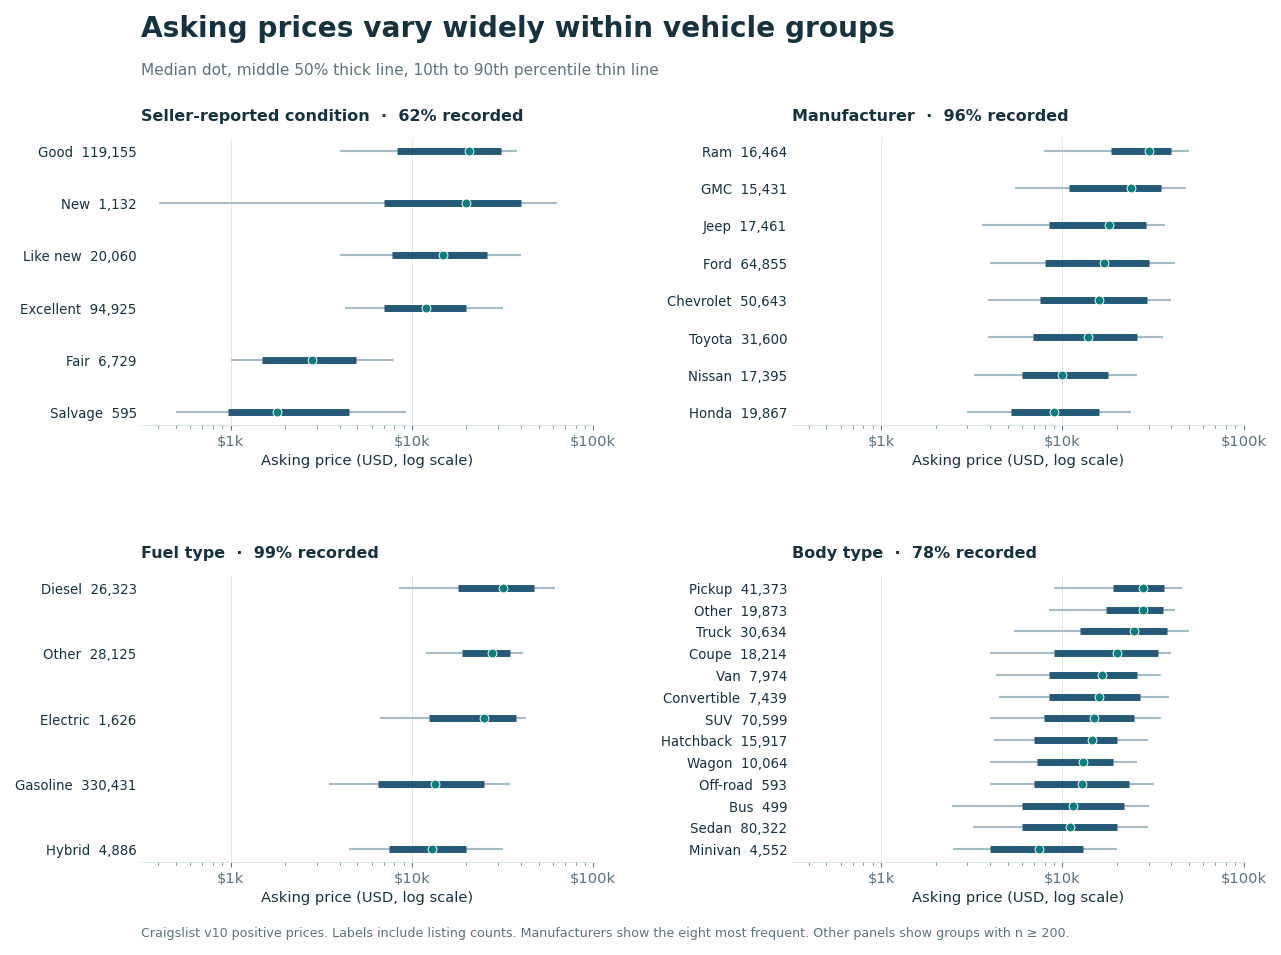

In [2]:
coverage, distributions = profile_groups(data)
coverage_show = coverage.rename(columns={
    "field": "Field", "known": "Recorded", "unknown": "Unreported", "known_share": "Recorded share",
})
display(coverage_show.style.hide(axis="index").format({
    "Recorded": "{:,}", "Unreported": "{:,}", "Recorded share": "{:.1%}",
}))
save_figure(distribution_figure(coverage, distributions), "01_group_distributions")


Body type is recorded on 78.2% of listings and condition on 61.6%. The chart displays wide within-group spreads alongside the between-group medians. Listing counts describe the posted sample, and the denominators differ by field.

### Four contrasts and their overlap

The paired controls depend on the comparison. The two listed vehicle controls are separate from the group being compared.

Contrast,"Controls in addition to age, mileage and region"
Good − excellent,"make_stratum, type"
Ford − Chevrolet,"type, fuel"
Diesel − gas,"make_stratum, type"
Pickup − SUV,"make_stratum, fuel"


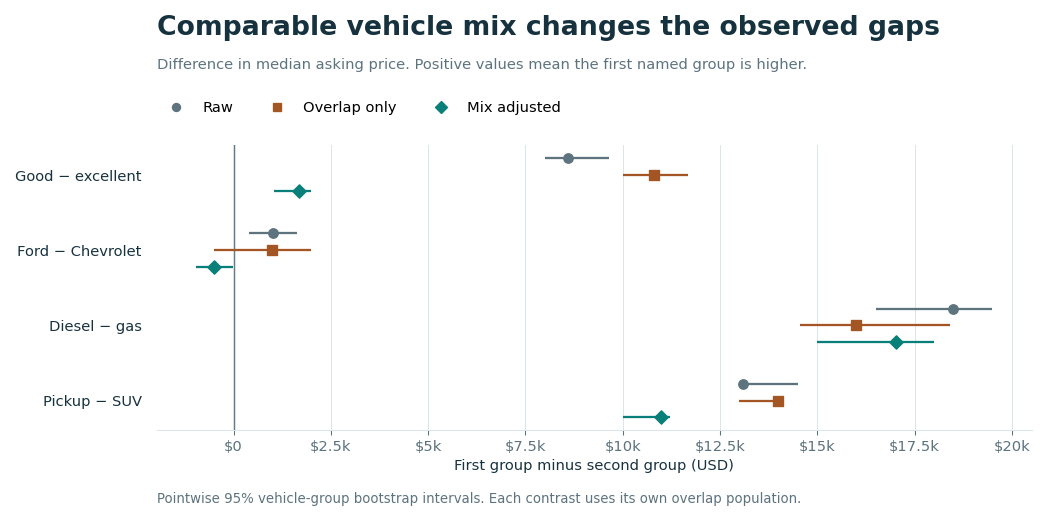

Contrast,Stage,First median,Second median,Gap (USD),95% lower,95% upper
Good − excellent,Raw,"20,590","11,987","8,603","8,002","9,640"
Good − excellent,Overlap only,"21,750","10,950","10,800","10,005","11,690"
Good − excellent,Mix adjusted,"12,980","11,300","1,680","1,043","1,991"
Ford − Chevrolet,Raw,"16,995","15,990","1,005",401,"1,632"
Ford − Chevrolet,Overlap only,"17,995","16,998",997,-495,"2,001"
Ford − Chevrolet,Mix adjusted,"16,995","17,500",-505,-956,-3
Diesel − gas,Raw,"31,990","13,500","18,490","16,500","19,495"
Diesel − gas,Overlap only,"39,999","23,995","16,004","14,562","18,414"
Diesel − gas,Mix adjusted,"41,980","24,950","17,030","15,004","18,000"
Pickup − SUV,Raw,"27,999","14,900","13,099","12,995","14,491"


In [3]:
design = pd.DataFrame([
    {"Contrast": item.label, "Controls in addition to age, mileage and region": ", ".join(item.controls)}
    for item in COMPARISONS
])
display(design.style.hide(axis="index"))

with threadpool_limits(limits=2):
    fitted = [compare_groups(data, item, draws=BOOTSTRAPS, seed=SEED + i)
              for i, item in enumerate(COMPARISONS)]

estimates = pd.concat([fit["estimates"] for fit in fitted], ignore_index=True)
support = pd.concat([fit["support"] for fit in fitted], ignore_index=True)
balance = pd.concat([fit["balance"] for fit in fitted], ignore_index=True)
save_figure(contrast_figure(estimates), "02_overlap_weighted_contrasts")

estimate_show = estimates.rename(columns={
    "comparison": "Contrast", "stage": "Stage", "median_first": "First median", "median_second": "Second median",
    "gap": "Gap (USD)", "lo": "95% lower", "hi": "95% upper",
})
display(estimate_show.style.hide(axis="index").format({
    key: "{:,.0f}" for key in ("First median", "Second median", "Gap (USD)", "95% lower", "95% upper")
}))


The good versus excellent gap widened when the sample was restricted to shared strata and then narrowed after weighting. This distinguishes changes in who entered the comparison from changes in the mix within that subset. The Ford–Chevrolet point estimate changed sign after weighting.

### Check how much data supports each estimate

Retention is relative to all listings in the named raw group. Effective sample sizes (ESS) summarize weight concentration. Vehicle ESS first adds weights within vehicle groups. Standardized mean differences (SMDs) use a common unweighted pooled standard deviation for before and after. Coarsened strata balance by construction and SMDs check the original continuous values.

In [4]:
support_show = support.rename(columns={
    "comparison": "Contrast", "group": "Group", "raw_n": "Raw listings", "overlap_n": "Shared listings",
    "retained": "Retained share", "listing_ess": "Listing ESS", "vehicle_ess": "Vehicle ESS", "strata": "Shared strata",
})
display(support_show.style.hide(axis="index").format({
    "Raw listings": "{:,}", "Shared listings": "{:,}", "Retained share": "{:.1%}",
    "Listing ESS": "{:,.0f}", "Vehicle ESS": "{:,.0f}", "Shared strata": "{:,}",
}))
display(balance.rename(columns={
    "comparison": "Contrast", "feature": "Original covariate", "raw_smd": "Raw SMD", "adjusted_smd": "Adjusted SMD",
}).style.hide(axis="index").format({"Raw SMD": "{:+.3f}", "Adjusted SMD": "{:+.3f}"}))


Contrast,Group,Raw listings,Shared listings,Retained share,Listing ESS,Vehicle ESS,Shared strata
Good − excellent,good,"119,155","51,018",42.8%,"33,265","5,503",540
Good − excellent,excellent,"94,925","40,740",42.9%,"34,785","12,285",540
Ford − Chevrolet,ford,"64,855","32,019",49.4%,"30,243","2,463",290
Ford − Chevrolet,chevrolet,"50,643","26,848",53.0%,"25,769","2,485",290
Diesel − gas,diesel,"26,323","7,940",30.2%,"7,589","1,142",127
Diesel − gas,gas,"330,431","27,612",8.4%,"16,693","3,369",127
Pickup − SUV,pickup,"41,373","18,424",44.5%,"16,126","1,128",173
Pickup − SUV,suv,"70,599","22,870",32.4%,"19,062","4,488",173


Contrast,Original covariate,Raw SMD,Adjusted SMD
Good − excellent,vehicle_age,-0.212,+0.007
Good − excellent,odometer,-0.407,-0.016
Ford − Chevrolet,vehicle_age,-0.068,+0.024
Ford − Chevrolet,odometer,+0.073,-0.004
Diesel − gas,vehicle_age,-0.002,-0.018
Diesel − gas,odometer,+0.433,+0.023
Pickup − SUV,vehicle_age,-0.016,-0.007
Pickup − SUV,odometer,-0.194,-0.026


The diesel comparison retained 30.2% of diesel and 8.4% of gasoline listings. Its adjusted gap describes that shared subset, where diesel-compatible vehicle mixes appear in both groups.

### Check sensitivity to price and strata

Both alternative fits rebuild the support and its target weights. The price-band estimate describes positive listings inside USD 500–150,000. The finer specification uses nine age bands and nine mileage bands with the same vehicle controls and minimum cluster count, so it often retains fewer listings. These checks compare point estimates across different supported populations.

In [5]:
in_band = data.loc[data["price"].between(LOW_PRICE_REVIEW, HIGH_PRICE_REVIEW)]
checks = []
with threadpool_limits(limits=2):
    for case, frame, fine in [
        ("All positive prices", data, False),
        ("USD 500 to 150,000", in_band, False),
        ("Finer age and mileage bands", data, True),
    ]:
        for item in COMPARISONS:
            result = compare_groups(frame, item, fine=fine)
            row = result["estimates"].loc[lambda t: t["stage"].eq("Mix adjusted")].iloc[0]
            first, second = result["support"]["retained"]
            checks.append({
                "contrast": item.label, "specification": case, "gap": float(row["gap"]),
                "first_retained": first, "second_retained": second,
            })
sensitivity = pd.DataFrame(checks)
display(sensitivity.rename(columns={
    "contrast": "Contrast", "specification": "Specification", "gap": "Adjusted gap (USD)",
    "first_retained": "First retained", "second_retained": "Second retained",
}).style.hide(axis="index").format({
    "Adjusted gap (USD)": "{:+,.0f}", "First retained": "{:.1%}", "Second retained": "{:.1%}",
}))


Contrast,Specification,Adjusted gap (USD),First retained,Second retained
Good − excellent,All positive prices,"+1,680",42.8%,42.9%
Ford − Chevrolet,All positive prices,-505,49.4%,53.0%
Diesel − gas,All positive prices,"+17,030",30.2%,8.4%
Pickup − SUV,All positive prices,"+10,995",44.5%,32.4%
Good − excellent,"USD 500 to 150,000",+800,40.9%,42.6%
Ford − Chevrolet,"USD 500 to 150,000",-857,49.2%,52.9%
Diesel − gas,"USD 500 to 150,000","+17,000",30.0%,8.2%
Pickup − SUV,"USD 500 to 150,000","+10,990",44.4%,32.5%
Good − excellent,Finer age and mileage bands,"+2,400",19.6%,19.4%
Ford − Chevrolet,Finer age and mileage bands,-45,34.0%,36.9%


The condition difference remains positive across these checks, with adjusted estimates of USD 800 to USD 2,400. The finely balanced Ford–Chevrolet estimate moves close to zero. Pickup and diesel remain higher in their respective shared populations.

### Follow the condition comparison through the distribution

The age-band table checks whether the weighted condition comparison is similar in younger and older listings. Band results summarize the weighted shared sample within each age range and show bands with at least 200 listings in both groups.

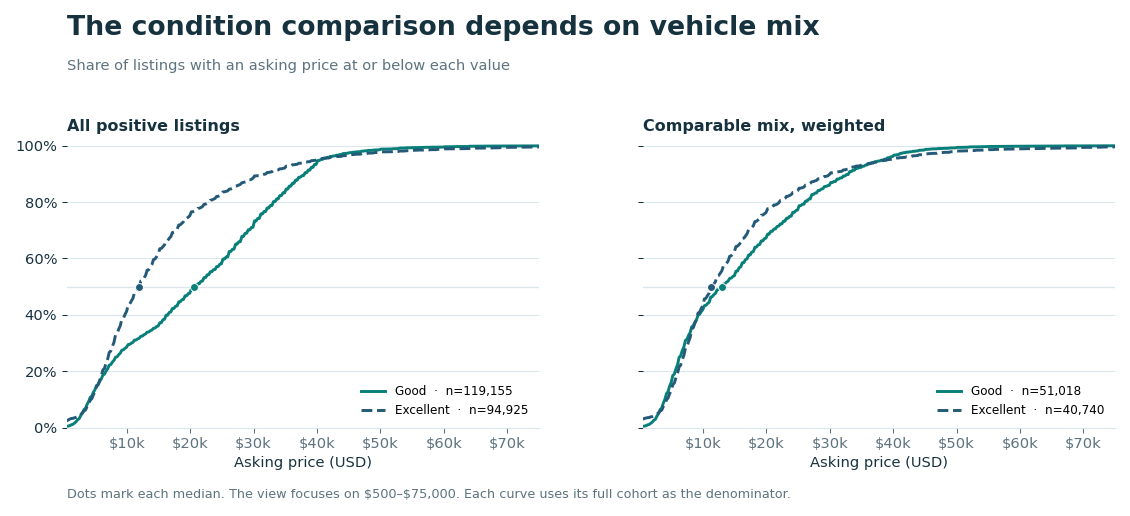

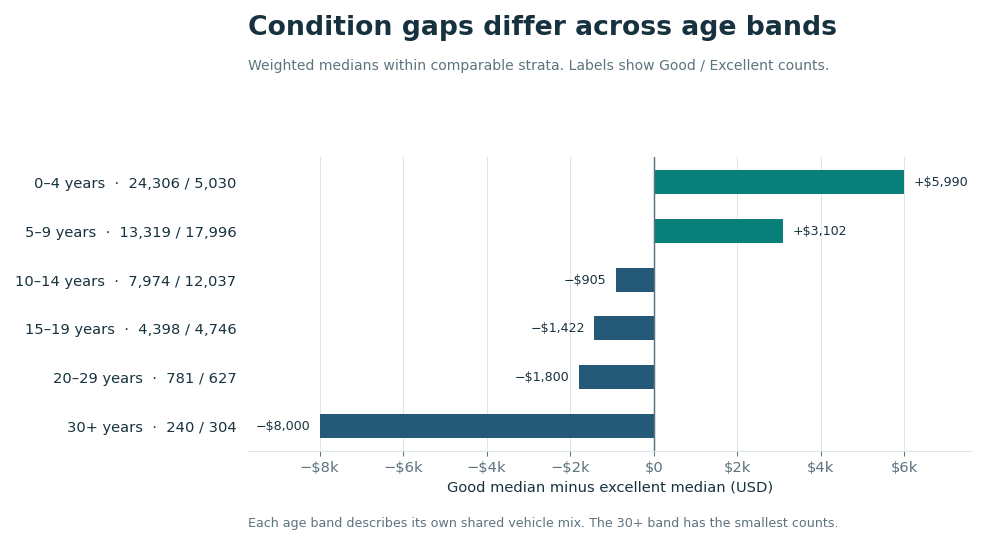

Age (years),Good listings,Excellent listings,Good median (USD),Excellent median (USD),Gap (USD)
0–4,"24,306","5,030","28,990","23,000","+5,990"
5–9,"13,319","17,996","16,990","13,888","+3,102"
10–14,"7,974","12,037","6,995","7,900",-905
15–19,"4,398","4,746","4,500","5,922","-1,422"
20–29,781,627,"3,600","5,400","-1,800"
30+,240,304,"10,500","18,500","-8,000"


In [6]:
condition_fit = fitted[0]
save_figure(
    condition_cdf_figure(data, condition_fit["overlap"], condition_fit["estimates"]),
    "03_condition_distributions",
)
condition_age_gap = condition_contrast_by_age(condition_fit["overlap"])
save_figure(condition_age_figure(condition_age_gap), "04_condition_gap_by_age")
display(condition_age_gap.rename(columns={
    "age_years": "Age (years)", "good_n": "Good listings", "excellent_n": "Excellent listings",
    "good_median": "Good median (USD)", "excellent_median": "Excellent median (USD)",
    "good_minus_excellent": "Gap (USD)",
}).style.hide(axis="index").format({
    "Good listings": "{:,}", "Excellent listings": "{:,}", "Good median (USD)": "{:,.0f}",
    "Excellent median (USD)": "{:,.0f}", "Gap (USD)": "{:+,.0f}",
}))


Within the adjusted age bands, good is higher at ages 0–4 and 5–9. Excellent is higher in every displayed band from age 10 onward, by USD 905 at ages 10–14 and USD 1,422 at ages 15–19. The 30+ group has the smallest sample, with 240 good and 304 excellent listings.

### Describe unreported condition

A missing condition label forms its own descriptive cohort. It accounts for 38.4% of positive-price listings, and the proportion varies by vehicle age. The table shows the number of usable observations alongside age and mileage medians.

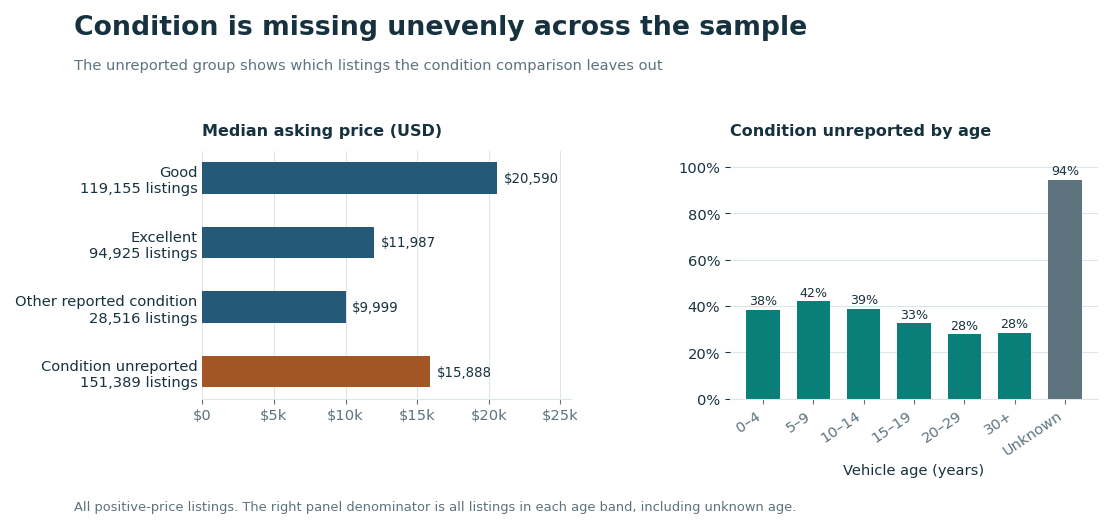

,Listings,Median price (USD),Known age,Median age (years),Usable mileage,Median mileage (mi)
status,,,,,,
Condition unreported,"151,389","15,888","150,181",7,"149,933","91,258"
Excellent,"94,925","11,987","94,888",9,"93,070","103,574"
Good,"119,155","20,590","119,152",6,"118,755","52,294"
Other reported condition,"28,516","9,999","28,485",10,"28,357","94,000"


In [7]:
condition, condition_missing_by_age = summarize_condition(data)
save_figure(condition_coverage_figure(condition, condition_missing_by_age), "05_condition_missingness")
display(condition.rename(columns={
    "n": "Listings", "median_price": "Median price (USD)", "age_n": "Known age",
    "median_age": "Median age (years)", "mileage_n": "Usable mileage", "median_mileage": "Median mileage (mi)",
}).style.format("{:,.0f}"))


## Takeaways

- **Vehicle mix accounts for part of the descriptive condition gap.** The weighted medians remain separated by much less than the raw medians. The direction differs by age. Good leads in the two youngest bands, and excellent leads in every displayed band from age 10 onward. Seller-reported labels and unmeasured attributes still affect interpretation.
- **The Ford–Chevrolet estimate is small and sensitive to specification.** Fuel and body-type contrasts are larger in the subsets where both groups appear, and overlap limits the target population.
- **Condition nonreporting varies by age.** The four cohorts in the summary have different price, age and mileage profiles. The condition comparison applies to listings with recorded labels and shared covariates.

This analysis describes asking prices in one snapshot. Residual trim and equipment differences, seller reporting, the limited overlap of some groups, inferred vehicle identities and unrecorded condition limit generalization.

In [8]:
def records(frame):
    return json.loads(frame.to_json(orient="records", double_precision=12))

aggregate = {
    "source": "Austin Reese, Craigslist Cars & Trucks Data, Kaggle version 10",
    "positive_listings": len(data),
    "bootstrap_draws": BOOTSTRAPS,
    "coverage": records(coverage),
    "contrasts": records(estimates),
    "overlap": records(support),
    "balance": records(balance),
    "sensitivity": records(sensitivity),
    "condition_profile": records(condition.reset_index()),
    "condition_unreported_by_age": records(condition_missing_by_age.reset_index()),
    "condition_contrasts_by_age": records(condition_age_gap),
}
(figure_dir / "summary.json").write_text(json.dumps(aggregate, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Aggregate summary and five chart pairs saved under outputs/q3.")


Aggregate summary and five chart pairs saved under outputs/q3.
